# 10장. 시계열 딥러닝 기반 가상계측 심화

「AI로 만드는 제조공정 품질관리 따라하기」 10장 실습 Notebook입니다.
Colab에서는 [런타임] → [런타임 유형 변경]에서 GPU(T4)를 선택하면 빨라집니다. CPU로도 실행됩니다.
평가 기준은 8장과 같습니다: training으로 학습하고 공식 validation+test(848건)로 평가합니다.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/02-virtual-metrology

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit

from src.cmp_utils import (KEY, SEED, build_table, feature_columns, load_cmp, make_models,
                           make_sequences, regression_report, time_knn_predict)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Python", platform.python_version(), "| PyTorch", torch.__version__, "| 장치", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor())

Python 3.12.9 | PyTorch 2.15.0+cpu | 장치 cpu Intel64 Family 6 Model 165 Stepping 5, GenuineIntel


## 10-1. 시계열 입력 텐서 만들기

In [3]:
data = load_cmp()
tabs = {split: build_table(*v) for split, v in data.items()}
train = tabs["train"]
train = train[train["AVG_REMOVAL_RATE"] < 1000].reset_index(drop=True)
hold = pd.concat([tabs["val"], tabs["test"]], ignore_index=True)
hold_sensors = pd.concat([data["val"][0], data["test"][0]], ignore_index=True)

L = 128
t = time.perf_counter()
seq_tr = make_sequences(data["train"][0], train[KEY], length=L)
seq_ho = make_sequences(hold_sensors, hold[KEY], length=L)
print("시계열 텐서:", seq_tr.shape, seq_ho.shape, f"({time.perf_counter() - t:.1f}초)")

시계열 텐서: (1977, 128, 19) (848, 128, 19) (1.8초)


In [4]:
# 채널별 표준화 (training 통계만 사용)
mu, sd = seq_tr.reshape(-1, seq_tr.shape[2]).mean(0), seq_tr.reshape(-1, seq_tr.shape[2]).std(0) + 1e-6
seq_tr_n, seq_ho_n = (seq_tr - mu) / sd, (seq_ho - mu) / sd

# 정적 입력: 공정 그룹(원-핫), 소요 시간·행 수(로그) — 길이를 128로 맞추면서 사라지는 정보
def static_feats(tab):
    s = pd.get_dummies(tab["grp"]).reindex(columns=["A123", "A456", "B"], fill_value=0).astype(float)
    s["log_dur"] = np.log1p(tab["duration"])
    s["log_rows"] = np.log1p(tab["n_rows"])
    return s.to_numpy(np.float32)

st_tr, st_ho = static_feats(train), static_feats(hold)
st_mu, st_sd = st_tr.mean(0), st_tr.std(0) + 1e-6
st_tr, st_ho = (st_tr - st_mu) / st_sd, (st_ho - st_mu) / st_sd

# 목표: 그룹 평균을 뺀 잔차를 예측하고, 마지막에 그룹 평균을 더한다
gmean = train.groupby("grp")["AVG_REMOVAL_RATE"].mean()
base_tr, base_ho = train["grp"].map(gmean).to_numpy(), hold["grp"].map(gmean).to_numpy()
y_tr, y_ho = train["AVG_REMOVAL_RATE"].to_numpy(), hold["AVG_REMOVAL_RATE"].to_numpy()
r_sd = float(np.std(y_tr - base_tr))
target_tr = ((y_tr - base_tr) / r_sd).astype(np.float32)

# 조기 종료용 내부 검증: training 웨이퍼의 15% (웨이퍼 단위)
inner_tr, inner_va = next(GroupShuffleSplit(1, test_size=0.15, random_state=SEED).split(train, groups=train["WAFER_ID"]))
print("내부 학습/검증:", len(inner_tr), len(inner_va), "| 잔차 표준편차:", round(r_sd, 3))

내부 학습/검증: 1679 298 | 잔차 표준편차: 7.424


### 모델 정의: LSTM과 TCN

In [5]:
class LSTMReg(nn.Module):
    def __init__(self, n_ch, n_static, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_ch, hidden, num_layers=2, batch_first=True, dropout=0.2)
        self.head = nn.Sequential(nn.Linear(hidden + n_static, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))

    def forward(self, x, s):
        _, (h, _) = self.lstm(x)              # h: (층 수, 배치, hidden) — 마지막 층의 마지막 상태를 쓴다
        return self.head(torch.cat([h[-1], s], dim=1)).squeeze(1)


class TCNBlock(nn.Module):
    def __init__(self, c_in, c_out, dilation, k=3):
        super().__init__()
        pad = (k - 1) * dilation
        self.conv1 = nn.Conv1d(c_in, c_out, k, padding=pad, dilation=dilation)
        self.conv2 = nn.Conv1d(c_out, c_out, k, padding=pad, dilation=dilation)
        self.pad = pad
        self.drop = nn.Dropout(0.2)
        self.skip = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x):                     # x: (배치, 채널, 길이)
        out = torch.relu(self.conv1(x)[..., :-self.pad])    # 오른쪽을 잘라 인과(causal) 합성곱으로 만든다
        out = self.drop(torch.relu(self.conv2(out)[..., :-self.pad]))
        return torch.relu(out + self.skip(x))


class TCNReg(nn.Module):
    def __init__(self, n_ch, n_static, channels=32, dilations=(1, 2, 4, 8, 16)):
        super().__init__()
        layers, c = [], n_ch
        for d in dilations:
            layers.append(TCNBlock(c, channels, d))
            c = channels
        self.tcn = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Linear(2 * channels + n_static, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))

    def forward(self, x, s):
        h = self.tcn(x.transpose(1, 2))       # (배치, 채널, 길이)
        feat = torch.cat([h.mean(dim=2), h[..., -1], s], dim=1)   # 전체 평균 + 마지막 시점
        return self.head(feat).squeeze(1)


def receptive_field(dilations=(1, 2, 4, 8, 16), k=3):
    return 1 + sum(2 * (k - 1) * d for d in dilations)

print("TCN 수용 영역(receptive field):", receptive_field(), "시점 / 입력 길이", L)

TCN 수용 영역(receptive field): 125 시점 / 입력 길이 128


In [6]:
def to_t(*arrs):
    return [torch.tensor(a, dtype=torch.float32, device=DEVICE) for a in arrs]

def train_model(make, seed, max_epochs=150, patience=15, batch=64, lr=1e-3):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = make().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    xtr, stt, ytr = to_t(seq_tr_n[inner_tr], st_tr[inner_tr], target_tr[inner_tr])
    xva, stv, yva = to_t(seq_tr_n[inner_va], st_tr[inner_va], target_tr[inner_va])
    best, best_state, wait, hist = np.inf, None, 0, []
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    for epoch in range(max_epochs):
        model.train()
        idx = rng.permutation(len(xtr))
        tl = 0.0
        for i in range(0, len(idx), batch):
            b = idx[i:i + batch]
            opt.zero_grad()
            loss = nn.functional.mse_loss(model(xtr[b], stt[b]), ytr[b])
            loss.backward()
            opt.step()
            tl += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            vl = nn.functional.mse_loss(model(xva, stv), yva).item()
        hist.append((tl / len(xtr), vl))
        if vl < best - 1e-4:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, hist, time.perf_counter() - t0

def predict(model, seq, st):
    model.eval()
    x, s = to_t(seq, st)
    t0 = time.perf_counter()
    with torch.no_grad():
        out = model(x, s).cpu().numpy()
    return out, time.perf_counter() - t0

## 10-1·10-2. 학습과 평가 (시드 3개)

In [7]:
n_ch, n_st = seq_tr.shape[2], st_tr.shape[1]
makers = {"LSTM": lambda: LSTMReg(n_ch, n_st), "TCN": lambda: TCNReg(n_ch, n_st)}
deep = {}
for name, make in makers.items():
    runs = []
    for seed in [SEED, SEED + 1, SEED + 2]:
        model, hist, sec = train_model(make, seed)
        z, inf_sec = predict(model, seq_ho_n, st_ho)
        pred = base_ho + z * r_sd
        rep = regression_report(y_ho, pred, hold["grp"])
        runs.append({"seed": seed, "epochs": len(hist), "train_sec": sec, "infer_sec": inf_sec,
                     "MAE": rep.loc["전체", "MAE"], "RMSE": rep.loc["전체", "RMSE"], "report": rep, "hist": hist, "pred": pred})
        print(f"{name} seed {seed}: epoch {len(hist):3d} | 학습 {sec:5.1f}초 | 평가 MAE {rep.loc['전체', 'MAE']:.3f} RMSE {rep.loc['전체', 'RMSE']:.3f}")
    deep[name] = {"runs": runs, "params": sum(p.numel() for p in make().parameters())}

LSTM seed 42: epoch  51 | 학습  45.0초 | 평가 MAE 3.176 RMSE 4.198


LSTM seed 43: epoch  39 | 학습  32.6초 | 평가 MAE 3.220 RMSE 4.202


LSTM seed 44: epoch  32 | 학습  26.2초 | 평가 MAE 3.249 RMSE 4.246


TCN seed 42: epoch  51 | 학습  58.7초 | 평가 MAE 2.914 RMSE 3.798


TCN seed 43: epoch  43 | 학습  51.1초 | 평가 MAE 2.897 RMSE 3.777


TCN seed 44: epoch  48 | 학습  55.8초 | 평가 MAE 2.906 RMSE 3.727


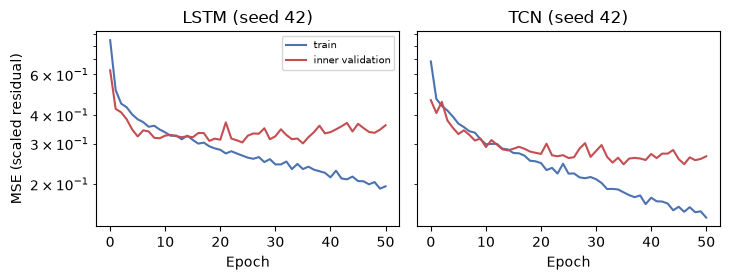

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.9), sharey=True)
for ax, name in zip(axes, ["LSTM", "TCN"]):
    h = np.array(deep[name]["runs"][0]["hist"])
    ax.plot(h[:, 0], label="train", color="#4C72B0")
    ax.plot(h[:, 1], label="inner validation", color="#C44E52")
    ax.set(title=f"{name} (seed {SEED})", xlabel="Epoch")
    ax.set_yscale("log")
axes[0].set_ylabel("MSE (scaled residual)")
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig("results/10_learning_curves.png", dpi=150)
plt.show()

## 10-3. 같은 분리 기준에서 통계 특징 모델과 비교

In [9]:
cols = feature_columns(train)
X, Xh = train[cols], hold[cols]
compare = {}
for name in ["RandomForest", "XGBoost"]:
    mdl = clone(make_models()[name])
    t0 = time.perf_counter(); mdl.fit(X, y_tr); fit_sec = time.perf_counter() - t0
    t0 = time.perf_counter(); p = mdl.predict(Xh); inf_sec = time.perf_counter() - t0
    compare[name] = {"report": regression_report(y_ho, p, hold["grp"]), "train_sec": fit_sec, "infer_sec": inf_sec}
p_knn = time_knn_predict(train, hold, k=10)
compare["시각 kNN"] = {"report": regression_report(y_ho, p_knn, hold["grp"]), "train_sec": 0.0, "infer_sec": 0.0}
compare["GroupMean"] = {"report": regression_report(y_ho, base_ho, hold["grp"]), "train_sec": 0.0, "infer_sec": 0.0}

rows = []
for name, v in compare.items():
    r = v["report"]
    rows.append({"model": name, "MAE": r.loc["전체", "MAE"], "MAE_sd": 0.0, "RMSE": r.loc["전체", "RMSE"],
                 **{f"R2_{g}": r.loc[g, "R2"] for g in ["A123", "A456", "B"]},
                 "train_sec": v["train_sec"], "infer_sec": v["infer_sec"]})
for name, v in deep.items():
    reps = [r["report"] for r in v["runs"]]
    rows.append({"model": name, "MAE": np.mean([r.loc["전체", "MAE"] for r in reps]),
                 "MAE_sd": np.std([r.loc["전체", "MAE"] for r in reps]),
                 "RMSE": np.mean([r.loc["전체", "RMSE"] for r in reps]),
                 **{f"R2_{g}": np.mean([r.loc[g, "R2"] for r in reps]) for g in ["A123", "A456", "B"]},
                 "train_sec": np.mean([r["train_sec"] for r in v["runs"]]),
                 "infer_sec": np.mean([r["infer_sec"] for r in v["runs"]])})
table = pd.DataFrame(rows).set_index("model")
print(table.round(3))
print("파라미터 수:", {k: v["params"] for k, v in deep.items()})

                MAE  MAE_sd   RMSE  R2_A123  R2_A456   R2_B  train_sec  \
model                                                                    
RandomForest  2.497   0.000  3.353    0.419    0.800  0.823      2.167   
XGBoost       2.529   0.000  3.374    0.264    0.739  0.862      0.774   
시각 kNN        2.127   0.000  2.858    0.450    0.845  0.886      0.000   
GroupMean     5.827   0.000  7.454   -0.011   -0.014 -0.003      0.000   
LSTM          3.215   0.030  4.215    0.253    0.632  0.734     34.605   
TCN           2.906   0.007  3.767    0.203    0.685  0.814     55.220   

              infer_sec  
model                    
RandomForest      0.100  
XGBoost           0.008  
시각 kNN            0.000  
GroupMean         0.000  
LSTM              0.074  
TCN               0.115  
파라미터 수: {'LSTM': 59585, 'TCN': 34977}


In [10]:
# 시퀀스 모델의 잔차가 시각 kNN과 얼마나 비슷한가 (같은 정보를 쓰는지 확인)
for name in ["LSTM", "TCN"]:
    pm = np.mean([r["pred"] for r in deep[name]["runs"]], axis=0)
    print(name, "3개 시드 평균 예측 MAE:", round(float(np.mean(np.abs(pm - y_ho))), 3),
          "| XGBoost 잔차와의 상관:", round(float(np.corrcoef(y_ho - pm, y_ho - make_models()["XGBoost"].fit(X, y_tr).predict(Xh))[0, 1]), 3))

LSTM 3개 시드 평균 예측 MAE: 3.129 | XGBoost 잔차와의 상관: 0.697


TCN 3개 시드 평균 예측 MAE: 2.824 | XGBoost 잔차와의 상관: 0.758


In [11]:
result = {
    "device": DEVICE, "torch": torch.__version__, "seq_len": L, "n_channels": int(n_ch), "n_static": int(n_st),
    "inner_split": [int(len(inner_tr)), int(len(inner_va))], "receptive_field": receptive_field(),
    "params": {k: int(v["params"]) for k, v in deep.items()},
    "deep_runs": {k: [{kk: (round(float(vv), 3) if isinstance(vv, (float, np.floating)) else vv)
                       for kk, vv in r.items() if kk in ("seed", "epochs", "train_sec", "infer_sec", "MAE", "RMSE")}
                      for r in v["runs"]] for k, v in deep.items()},
    "table": {m: {k: round(float(v), 3) for k, v in row.items()} for m, row in table.iterrows()},
}
Path("results/10_deep.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(result["table"], ensure_ascii=False, indent=1))

{
 "RandomForest": {
  "MAE": 2.497,
  "MAE_sd": 0.0,
  "RMSE": 3.353,
  "R2_A123": 0.419,
  "R2_A456": 0.8,
  "R2_B": 0.823,
  "train_sec": 2.167,
  "infer_sec": 0.1
 },
 "XGBoost": {
  "MAE": 2.529,
  "MAE_sd": 0.0,
  "RMSE": 3.374,
  "R2_A123": 0.264,
  "R2_A456": 0.739,
  "R2_B": 0.862,
  "train_sec": 0.774,
  "infer_sec": 0.008
 },
 "시각 kNN": {
  "MAE": 2.127,
  "MAE_sd": 0.0,
  "RMSE": 2.858,
  "R2_A123": 0.45,
  "R2_A456": 0.845,
  "R2_B": 0.886,
  "train_sec": 0.0,
  "infer_sec": 0.0
 },
 "GroupMean": {
  "MAE": 5.827,
  "MAE_sd": 0.0,
  "RMSE": 7.454,
  "R2_A123": -0.011,
  "R2_A456": -0.014,
  "R2_B": -0.003,
  "train_sec": 0.0,
  "infer_sec": 0.0
 },
 "LSTM": {
  "MAE": 3.215,
  "MAE_sd": 0.03,
  "RMSE": 4.215,
  "R2_A123": 0.253,
  "R2_A456": 0.632,
  "R2_B": 0.734,
  "train_sec": 34.605,
  "infer_sec": 0.074
 },
 "TCN": {
  "MAE": 2.906,
  "MAE_sd": 0.007,
  "RMSE": 3.767,
  "R2_A123": 0.203,
  "R2_A456": 0.685,
  "R2_B": 0.814,
  "train_sec": 55.22,
  "infer_sec": 0.115
 